<a href="https://colab.research.google.com/github/Alejandra300905/NLP_Polarity_of_film_reviews_and_the_problem_of_negation/blob/main/ProyectoClasificacionR_Final_AlejandraB_CarlosM_NathalieL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R3.1 Polaridad de reseñas de cine y el problema de la negación

### Bitácora de Contribuciones del Equipo

| Etapa | Programó (Implementación) | Revisó (Código y Resultados) | Hizo la Presentación |
| :---: | :--- | :--- | :--- |
| **Etapa 1** | Carlos | Alejandra | Nathalie |
| **Etapa 2** | Alejandra | Nathalie | Carlos |
| **Etapa 3** | Nathalie | Carlos | Alejandra |


### Etapa 1 - **Análisis, representacion y baseline.** Limpieza (etiquetas HTML, puntuación) y división Train, Dev y Test. Baseline: bolsa de palabras de unigramas + Bayes ingenuo

In [1]:
import os
import tarfile
import pandas as pd
from google.colab import files
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

try:
  import gensim.downloader as api
  print("gemsim ya está instalada.")
except ImportError:
  print("gensim no encontrada. Instalando...")
  !pip install gensim
  import gensim.downloader as api

gensim no encontrada. Instalando...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 65.7 MB/s  0:00:00


In [2]:
tar_filename = 'aclImdb_v1.tar.gz'

# Si no existe la carpeta extraída, procedemos a obtener el archivo
if not os.path.exists('aclImdb'):
    if not os.path.exists(tar_filename):
        print("Por favor, sube tu archivo aclImdb_v1.tar.gz:")
        uploaded = files.upload()
        # Renombrar en caso de que se haya subido con otro nombre similar
        for name in uploaded.keys():
            if 'tar.gz' in name or 'gtarz' in name:
                os.rename(name, tar_filename)
                break

    print("Extrayendo aclImdb_v1.tar.gz...")
    with tarfile.open(tar_filename, 'r:gz') as tar:
        tar.extractall()

def load_imdb_dataset(base_dir):
    data = []
    for split in ['train', 'test']:
        for sentiment in ['pos', 'neg']:
            folder = os.path.join(base_dir, split, sentiment)
            label = 1 if sentiment == 'pos' else 0
            if os.path.exists(folder):
                for filename in os.listdir(folder):
                    if filename.endswith('.txt'):
                        with open(os.path.join(folder, filename), 'r', encoding='utf-8') as f:
                            review = f.read()
                            data.append({'review': review, 'sentiment': label, 'split': split})
    return pd.DataFrame(data)

Por favor, sube tu archivo aclImdb_v1.tar.gz:


Saving aclImdb_v1.tar.gz to aclImdb_v1.tar.gz
Extrayendo aclImdb_v1.tar.gz...


/tmp/ipykernel_1470/2390344328.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


In [3]:
# Cargar los datos en un DataFrame
df = load_imdb_dataset('aclImdb')

display(df.head())
display(df.info())

,review,sentiment,split
0,Normally the best way to annoy me in a film is...,1,train
1,Can any one help find out the title and artist...,1,train
2,***SPOILERS*** When undercover Brooklyn North ...,1,train
3,"for my opinion, the middle of the film, specia...",1,train
4,This film quite literally has every single act...,1,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  int64 
 2   split      50000 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


None

In [4]:
# Mostrar los valores únicos y la cantidad de registros para cada split
display(df['split'].value_counts())

,count
split,
train,25000
test,25000


In [5]:
# Mostrar algunas reseñas de ejemplo completas
#print("Ejemplo de Reseña Positiva:")
#print(df[df['sentiment'] ==1 ]['review'].iloc[0])
#print("\n" + "="*80 + "\n")
#print("Ejemplo de Reseña Negativa:")
#print(df[df['sentiment'] == 0]['review'].iloc[0])


count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


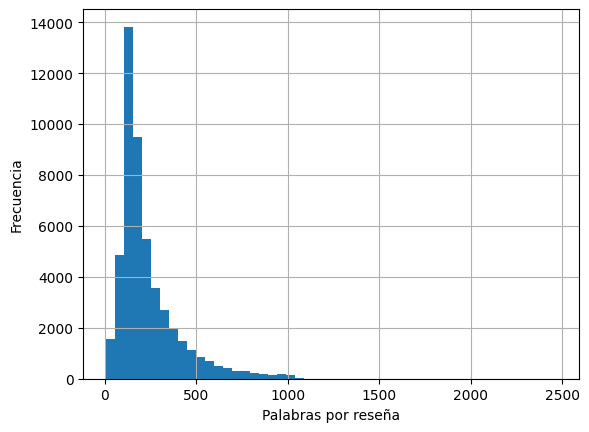

Con <br />: 29200


In [6]:
# Balance de clases y tamaño de cada partición
#print(df.groupby(["split", "sentiment"]).size().unstack())

# Longitud de reseñas (en palabras)
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

df["n_palabras"].hist(bins=50)
plt.xlabel("Palabras por reseña"); plt.ylabel("Frecuencia")
plt.show()

# ¿Cuántas reseñas tienen etiquetas HTML?
print("Con <br />:", df["review"].str.contains("<br", regex=False).sum())

In [7]:
# Encontrar los índices de las reseñas con menos y más palabras
idx_min = df['n_palabras'].idxmin()
idx_max = df['n_palabras'].idxmax()

print(f"=== RESEÑA CON MENOS PALABRAS ({df.loc[idx_min, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_min, 'sentiment'] == 1 else 'Negativo'}")
print(df.loc[idx_min, 'review'])
print("\n" + "="*50 + "\n")

print(f"=== RESEÑA CON MÁS PALABRAS ({df.loc[idx_max, 'n_palabras']} palabras) ===")
print(f"Sentiment: {'Positivo' if df.loc[idx_max, 'sentiment'] == 1 else 'Negativo'}")
# Mostramos los primeros 1500 caracteres para no saturar la pantalla, pero se puede imprimir completa
print(df.loc[idx_max, 'review'][:150] + '\n... [TRUNCADO]')

=== RESEÑA CON MENOS PALABRAS (4 palabras) ===
Sentiment: Negativo
Primary plot!Primary direction!Poor interpretation.


=== RESEÑA CON MÁS PALABRAS (2470 palabras) ===
Sentiment: Positivo
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag T
... [TRUNCADO]


In [8]:
def limpiar(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)      # quita etiquetas HTML
    texto = texto.lower()                        # minúsculas
    texto = re.sub(r"[^a-z' ]", " ", texto)      # quita puntuación, números y símbolos (conserva ')
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["clean"] = df["review"].apply(limpiar)
print(df.loc[1, "review"][:200])
print(df.loc[1, "clean"][:200])

Can any one help find out the title and artist of the song, that was played at least halfway through the movie. I can't remember what scene was playing. The words in the song are of a ballad. Some of 
can any one help find out the title and artist of the song that was played at least halfway through the movie i can't remember what scene was playing the words in the song are of a ballad some of the 


In [9]:
df.head()

,review,sentiment,split,n_palabras,clean
0,Normally the best way to annoy me in a film is...,1,train,84,normally the best way to annoy me in a film is...
1,Can any one help find out the title and artist...,1,train,131,can any one help find out the title and artist...
2,***SPOILERS*** When undercover Brooklyn North ...,1,train,688,spoilers when undercover brooklyn north det ed...
3,"for my opinion, the middle of the film, specia...",1,train,60,for my opinion the middle of the film speciall...
4,This film quite literally has every single act...,1,train,88,this film quite literally has every single act...


In [10]:
# Data split
train_full = df[df["split"] == "train"]
test = df[df["split"] == "test"]      # se queda intacto hasta el final

train, dev = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["sentiment"],
    random_state=42
)

print(len(train), len(dev), len(test))   # 20000, 5000, 25000

20000 5000 25000


In [11]:
vectorizer = CountVectorizer(
    ngram_range=(1,1),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2
)
X_train = vectorizer.fit_transform(train["clean"])   # fit SOLO con train
X_dev   = vectorizer.transform(dev["clean"])

y_train, y_dev = train["sentiment"], dev["sentiment"]
print("Vocabulario:", len(vectorizer.vocabulary_))

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)

Vocabulario: 42717


MultinomialNB()

In [12]:
# Tomamos el texto limpio de la primera fila del conjunto de train como ejemplo
"""
ejemplo_texto = train["clean"].iloc[2]
ejemplo_vectorizado = X_train[2]

print("Texto original limpio:")
print(ejemplo_texto)
print("\n" + "="*50 + "\n")

print("Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:")
print(ejemplo_vectorizado)
print("\n" + "="*50 + "\n")

# Mapeamos los IDs de vuelta a las palabras correspondientes del vocabulario
print("Palabras presentes en este texto y sus frecuencias:")
nombres_caracteristicas = vectorizer.get_feature_names_out()
coordenadas = ejemplo_vectorizado.tocoo()
for col, val in zip(coordenadas.col, coordenadas.data):
    print(f"- '{nombres_caracteristicas[col]}' (ID: {col}): {val} vez/veces")
"""

'\nejemplo_texto = train["clean"].iloc[2]\nejemplo_vectorizado = X_train[2]\n\nprint("Texto original limpio:")\nprint(ejemplo_texto)\nprint("\n" + "="*50 + "\n")\n\nprint("Representación en la Matriz Dispersa (Sparse Matrix) - (Fila, ID_Vocabulario) Frecuencia:")\nprint(ejemplo_vectorizado)\nprint("\n" + "="*50 + "\n")\n\n# Mapeamos los IDs de vuelta a las palabras correspondientes del vocabulario\nprint("Palabras presentes en este texto y sus frecuencias:")\nnombres_caracteristicas = vectorizer.get_feature_names_out()\ncoordenadas = ejemplo_vectorizado.tocoo()\nfor col, val in zip(coordenadas.col, coordenadas.data):\n    print(f"- \'{nombres_caracteristicas[col]}\' (ID: {col}): {val} vez/veces")\n'

In [13]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    print(f"── {nombre} ──")
    print(f"Exactitud: {accuracy_score(y, pred):.4f}")
    print(f"F1:        {f1_score(y, pred):.4f}")
    print(f"AUC-ROC:   {roc_auc_score(y, proba):.4f}")
    return pred

pred_dev = evaluar(nb, X_dev, y_dev, "Dev")
print(classification_report(y_dev, pred_dev, target_names=["neg", "pos"]))

# Test: úsalo UNA sola vez, cuando el baseline esté definitivo
#pred_test = evaluar(nb, X_test, y_test, "Test")

── Dev ──
Exactitud: 0.8452
F1:        0.8396
AUC-ROC:   0.9197
              precision    recall  f1-score   support

         neg       0.82      0.88      0.85      2500
         pos       0.87      0.81      0.84      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



In [14]:
# Seleccionamos una reseña del conjunto de desarrollo (por ejemplo, la primera)
indice_ejemplo = 0
texto_original = dev["review"].iloc[indice_ejemplo]
texto_limpio = dev["clean"].iloc[indice_ejemplo]
etiqueta_real = dev["sentiment"].iloc[indice_ejemplo]

# Transformamos el texto con el vectorizer para que tenga el formato adecuado
vector_ejemplo = X_dev[indice_ejemplo]

# Obtenemos las probabilidades de cada clase
probabilidades = nb.predict_proba(vector_ejemplo)[0]
prediccion = nb.predict(vector_ejemplo)[0]

print("=== TEXTO DE LA RESEÑA ===")
print(texto_original[:500] + ("..." if len(texto_original) > 500 else ""))
print("\n" + "="*30)
print(f"Etiqueta Real: {'Positivo (1)' if etiqueta_real == 1 else 'Negativo (0)'}")
print(f"Predicción del Modelo: {'Positivo (1)' if prediccion == 1 else 'Negativo (0)'}")
print("="*30)
print(f"Probabilidad de ser NEGATIVA (0): {probabilidades[0]:.6f} ({probabilidades[0]*100:.4f}%)")
print(f"Probabilidad de ser POSITIVA (1): {probabilidades[1]:.6f} ({probabilidades[1]*100:.4f}%)")


=== TEXTO DE LA RESEÑA ===
Anna (Ursula Andress) is brought in as an official R.N. by ex-lover Benito Varotto (Duilio Del Prete), ostensibly to nurse an aging widower, Count Leonida Bottacin (Mario Piso), back to health after a heart attack. But Benito is actually leading a group of heirs and businessmen, including American entrepreneur Mr. Kitch (Jack Palance), with ulterior motives, reflected by what Anna hopefully will actually accomplish with the Count. He has a history of, well, liking women, and would be actually a ...

Etiqueta Real: Positivo (1)
Predicción del Modelo: Positivo (1)
Probabilidad de ser NEGATIVA (0): 0.000000 (0.0000%)
Probabilidad de ser POSITIVA (1): 1.000000 (100.0000%)


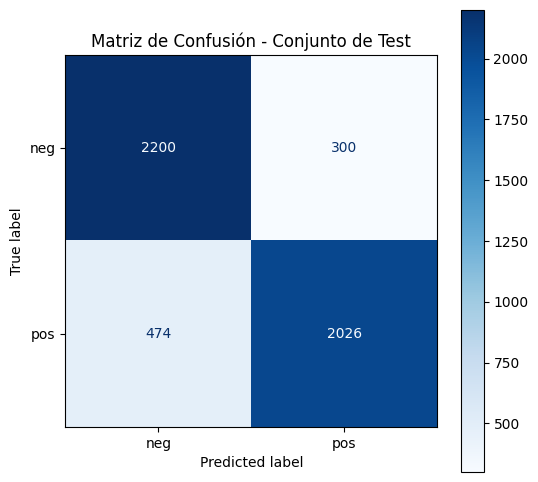

Verdaderos Negativos (TN): 2200
Falsos Positivos (FP): 300
Falsos Negativos (FN): 474
Verdaderos Positivos (TP): 2026


In [15]:
# Matriz confusion Bayes-Ingenuo
cm = confusion_matrix(y_dev, pred_dev)

# Crear la visualización de la matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

# Graficar la matriz
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión - Conjunto de Test")
plt.show()

# Imprimir también los valores numéricos directos
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


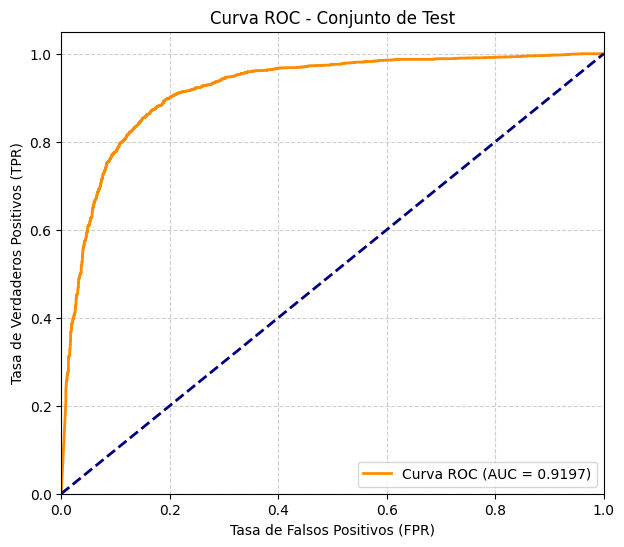

In [16]:
# Curva ROC Bayes-Ingenuo
proba_dev = nb.predict_proba(X_dev)[:, 1]

fpr, tpr, _ = roc_curve(y_dev, proba_dev)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Conjunto de Test')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Etapa 2 - **Primera aproximación**. TF-IDF de unigramas y bigramas + regresión logística, con y sin marcado de negación

2.1 Modelo A: TF-IDF (unigramas + bigramas) + Regresión Logística, **sin** marcado de negación

In [17]:
# TF-IDF con unigramas y bigramas sobre el texto limpio de la Etapa 1
tfidf_A = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2,
    sublinear_tf=True
)
XA_train = tfidf_A.fit_transform(train["clean"])   # fit SOLO con train
XA_dev   = tfidf_A.transform(dev["clean"])
print("Vocabulario (uni+bigramas):", len(tfidf_A.vocabulary_))

# Elegimos C (regularización) con el conjunto Dev
mejor_C_A, mejor_auc_A = 500, -1
'''
for C in [1, 5, 10, 50, 100, 200, 500]:
    m = LogisticRegression(C=C, max_iter=5000, solver="liblinear")
    m.fit(XA_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XA_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_A:
        mejor_C_A, mejor_auc_A = C, auc_dev
print("Mejor C:", mejor_C_A)
'''
lr_A = LogisticRegression(C=mejor_C_A, max_iter=10000, solver="liblinear")
lr_A.fit(XA_train, y_train)
pred_dev_A = evaluar(lr_A, XA_dev, y_dev, "Modelo A - Dev (sin negación)")
print(classification_report(y_dev, pred_dev_A, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas): 363192
── Modelo A - Dev (sin negación) ──
Exactitud: 0.9132
F1:        0.9136
AUC-ROC:   0.9692
              precision    recall  f1-score   support

         neg       0.92      0.91      0.91      2500
         pos       0.91      0.92      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Interpretación del Modelo A

En esta etapa se utilizó TF-IDF con unigramas y bigramas para representar numéricamente las reseñas. Posteriormente, entrenamos una regresión logística para clasificarlas como positivas o negativas.

El uso de bigramas permite considerar pares de palabras consecutivas y capturar expresiones como "not good".

2.2 Marcado de negación

In [18]:
NEGACIONES = {"not", "no", "never", "none", "nobody", "nothing", "nowhere",
              "neither", "nor", "cannot", "without", "hardly", "barely", "scarcely"}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*|[.,;:!?()]")   # palabras o signos de puntuación
PUNTUACION = set(".,;:!?()")

def es_negacion(tok):
    return tok in NEGACIONES or tok.endswith("n't")      # didn't, isn't, don't, can't...

def marcar_negacion(texto):
    texto = re.sub(r"<[^>]+>", " ", texto).lower()
    salida, en_negacion = [], False
    for tok in TOKEN_RE.findall(texto):
        if tok in PUNTUACION:                            # la puntuación cierra el alcance
            en_negacion = False
            continue                                     # y se descarta
        salida.append("NEG_" + tok if en_negacion else tok)
        if es_negacion(tok):                             # a partir de aquí, se marca
            en_negacion = True
    return " ".join(salida)

# Ejemplos para verificar la regla
ejemplos = [
    "This movie is not good, it was a waste.",
    "I didn't like the acting or the plot. Great music!",
    "Not bad at all<br />but never boring; fun",
]
for e in ejemplos:
    print("ORIGINAL:", e)
    print("MARCADO :", marcar_negacion(e), "\n")

df["clean_neg"] = df["review"].apply(marcar_negacion)
train = df.loc[train.index];
dev = df.loc[dev.index];
test = df.loc[test.index]   # mismas particiones, con la nueva columna
print(dev["clean_neg"].iloc[0][:300])

ORIGINAL: This movie is not good, it was a waste.
MARCADO : this movie is not NEG_good it was a waste 

ORIGINAL: I didn't like the acting or the plot. Great music!
MARCADO : i didn't NEG_like NEG_the NEG_acting NEG_or NEG_the NEG_plot great music 

ORIGINAL: Not bad at all<br />but never boring; fun
MARCADO : not NEG_bad NEG_at NEG_all NEG_but NEG_never NEG_boring fun 

anna ursula andress is brought in as an official r n by ex lover benito varotto duilio del prete ostensibly to nurse an aging widower count leonida bottacin mario piso back to health after a heart attack but benito is actually leading a group of heirs and businessmen including american entrepreneur 


### Marcado explícito de negación

La función identifica palabras de negación y marca los tokens siguientes con el prefijo `NEG_` hasta encontrar un signo de puntuación reconocido.

Esta transformación busca distinguir palabras como `good` y `NEG_good`.

2.3 Modelo B: TF-IDF (unigramas + bigramas) + Regresión Logística, **con** marcado de negación

In [19]:
tfidf_B = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[A-Za-z_]+(?:'[a-z]+)*",   # acepta NEG_palabra
    lowercase=False,                            # ya está en minúsculas; así no se altera NEG_
    min_df=2,
    sublinear_tf=True
)
XB_train = tfidf_B.fit_transform(train["clean_neg"])   # fit SOLO con train
XB_dev   = tfidf_B.transform(dev["clean_neg"])
print("Vocabulario (uni+bigramas, con NEG_):", len(tfidf_B.vocabulary_))
mejor_C_B, mejor_auc_B = 200, -1
"""
for C in [1, 5, 10, 50, 100, 200]:
    m = LogisticRegression(C=C, max_iter=5000, solver="liblinear")
    m.fit(XB_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XB_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_B:
        mejor_C_B, mejor_auc_B = C, auc_dev
print("Mejor C:", mejor_C_B)
"""
lr_B = LogisticRegression(C=mejor_C_B, max_iter=10000, solver="liblinear")
lr_B.fit(XB_train, y_train)
pred_dev_B = evaluar(lr_B, XB_dev, y_dev, "Modelo B - Dev (con negación)")
print(classification_report(y_dev, pred_dev_B, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas, con NEG_): 391601
── Modelo B - Dev (con negación) ──
Exactitud: 0.9102
F1:        0.9104
AUC-ROC:   0.9699
              precision    recall  f1-score   support

         neg       0.91      0.91      0.91      2500
         pos       0.91      0.91      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Entrenamiento del Modelo B

Se aplica TF-IDF al texto con negaciones marcadas y se entrena una regresión logística. Se mantiene el mismo procedimiento de selección de C utilizado en el Modelo A para facilitar la comparación.

2.4 Comparación: Baseline vs Modelo A vs Modelo B

In [20]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

resultados = {
    "Baseline: BoW + Naive Bayes":         (metricas(nb,   X_dev,  y_dev), metricas(nb,   X_dev,  y_dev)),
    "A: TF-IDF 1-2g + LR (sin negación)":  (metricas(lr_A, XA_dev, y_dev), metricas(lr_A, XA_dev, y_dev)),
    "B: TF-IDF 1-2g + LR (con negación)":  (metricas(lr_B, XB_dev, y_dev), metricas(lr_B, XB_dev, y_dev)),
}

filas = []
for nombre, (m_dev, m_test) in resultados.items():
    fila = {"Modelo": nombre}
    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    fila.update({f"Test {k}": v for k, v in m_test.items()})
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla)

# Efecto del marcado de negación (B - A) en Dev
print("\nMejora por marcado de negación (B - A) en Dev:")
for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = resultados["B: TF-IDF 1-2g + LR (con negación)"][1][k] - resultados["A: TF-IDF 1-2g + LR (sin negación)"][1][k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC,Test Exactitud,Test F1,Test AUC-ROC
Modelo,,,,,,
Baseline: BoW + Naive Bayes,0.8452,0.8396,0.9197,0.8452,0.8396,0.9197
A: TF-IDF 1-2g + LR (sin negación),0.9132,0.9136,0.9692,0.9132,0.9136,0.9692
B: TF-IDF 1-2g + LR (con negación),0.9102,0.9104,0.9699,0.9102,0.9104,0.9699



Mejora por marcado de negación (B - A) en Dev:
  Exactitud : -0.0030
  F1        : -0.0032
  AUC-ROC   : +0.0007


### Interpretación de resultados

El Modelo A y el Modelo B superan al baseline en las métricas evaluadas. El Modelo B obtiene una mejora pequeña respecto al Modelo A en F1 y AUC-ROC.

Estos resultados sugieren que el marcado explícito de negación aporta una mejora adicional en este conjunto de datos.

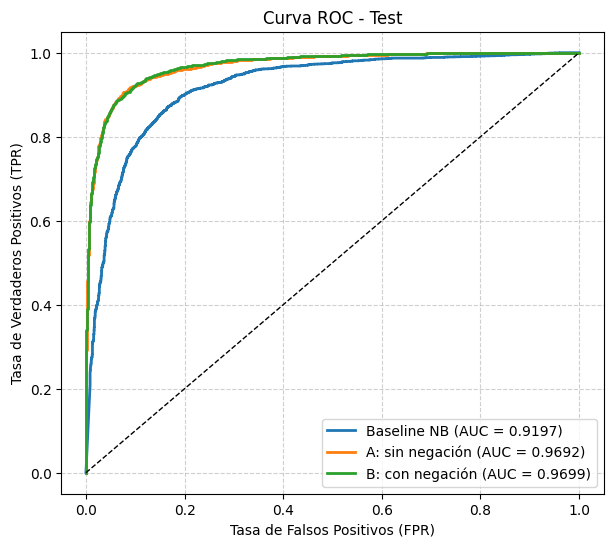

In [21]:
plt.figure(figsize=(7, 6))
for nombre, modelo, X in [("Baseline NB", nb, X_dev),
                          ("A: sin negación", lr_A, XA_dev),
                          ("B: con negación", lr_B, XB_dev)]:
    fpr, tpr, _ = roc_curve(y_dev, modelo.predict_proba(X)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Test"); plt.legend(loc="lower right"); plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### Curva ROC

Se compara la tasa de verdaderos positivos con la tasa de falsos positivos para distintos umbrales. El AUC resume la capacidad de discriminación de cada modelo.

El Modelo B presenta el AUC más alto, aunque la diferencia respecto al Modelo A es pequeña.

###Etapa 3- **Mejora**. Promedio de vectores Word2vec preentrenados + MLP; comparación con la Etapa 2

**Idea:** en lugar de contar palabras (BoW / TF-IDF), representamos cada palabra con un vector denso de 300 dimensiones
(Word2vec de Google News) y cada reseña como el **promedio** de los vectores de sus palabras.
Sobre esa representación entrenamos un MLP.

In [22]:
# Semillas para reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Word2vec de Google News (3 millones de palabras, 300 dimensiones).
# La primera vez descarga ~1.6 GB, puede tardar unos minutos.
w2v = api.load("word2vec-google-news-300")
print("Vocabulario:", len(w2v.key_to_index), "| Dimensión:", w2v.vector_size)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulario: 3000000 | Dimensión: 300


3.1 Representación de las reseñas: promedio de vectores Word2vec

Se usa el texto limpio de la Etapa 1 (`clean`), ya que Word2vec no contiene tokens como `NEG_good`. Las palabras que no existen en Word2vec se ignoran. Se usan las mismas particiones Train / Dev / Test de las etapas anteriores y se estandarizan los vectores (ajustando el escalador **solo** con Train).

In [23]:
def vector_promedio(texto):
    """Promedia los vectores Word2vec de las palabras de una reseña.
    Ignora palabras fuera del vocabulario; si no hay ninguna, regresa ceros."""
    vectores = [w2v[t] for t in texto.split() if t in w2v.key_to_index]
    if len(vectores) == 0:
        return np.zeros(w2v.vector_size, dtype=np.float32)
    return np.mean(vectores, axis=0)

# Matrices de entrada
Xw_train = np.vstack([vector_promedio(t) for t in train["clean"]])
Xw_dev   = np.vstack([vector_promedio(t) for t in dev["clean"]])

# Estandarización: fit SOLO con train
scaler = StandardScaler()
Xw_train = scaler.fit_transform(Xw_train)
Xw_dev   = scaler.transform(Xw_dev)

print("Train:", Xw_train.shape, "| Dev:", Xw_dev.shape)

Train: (20000, 300) | Dev: (5000, 300)


3.2 Modelo C: Word2vec promedio + MLP

Se entrena un MLP con dos capas ocultas (ReLU + Dropout) y una salida sigmoide. Se usa Dev para monitorear el entrenamiento y detenerlo cuando deja de mejorar; Test no se utiliza aquí.

In [24]:
# Diccionario con distintas arquitecturas de MLP a probar
arquitecturas = {
    "MLP_256_64": [
        layers.Input(shape=(300,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ],
    "MLP_128_32": [
        layers.Input(shape=(300,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ],
    "MLP_512_256_64": [
        layers.Input(shape=(300,)),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(1, activation="sigmoid")
    ]
}

modelos_entrenados = {}

# Iterar sobre las distintas arquitecturas definidas
for nombre, capas in arquitecturas.items():
    print(f"\n=== Entrenando arquitectura: {nombre} ===")

    # Fijar semillas antes de crear cada modelo para reproducibilidad
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    mlp_temp = keras.Sequential(capas)
    mlp_temp.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="roc_auc")]
        )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    historial = mlp_temp.fit(
        Xw_train, y_train.values,
        validation_data=(Xw_dev, y_dev.values),
        epochs=50,
        batch_size=128,
        callbacks=[early_stop],
        verbose=1
    )

    modelos_entrenados[nombre] = mlp_temp


=== Entrenando arquitectura: MLP_256_64 ===
Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.4253 - roc_auc: 0.8884 - val_loss: 0.3397 - val_roc_auc: 0.9309
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3428 - roc_auc: 0.9289 - val_loss: 0.3295 - val_roc_auc: 0.9350
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3188 - roc_auc: 0.9387 - val_loss: 0.3222 - val_roc_auc: 0.9377
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3039 - roc_auc: 0.9447 - val_loss: 0.3216 - val_roc_auc: 0.9385
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.2922 - roc_auc: 0.9485 - val_loss: 0.3204 - val_roc_auc: 0.9391
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.2812 - roc_auc: 0.9525 - val_loss: 0.3234 - val_roc_auc: 0.9391
Epoch 7/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2686 - roc_auc: 0.9565 - val_loss: 0.3245 - val_roc_auc: 0.9385
Epoch 8/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2592 - r

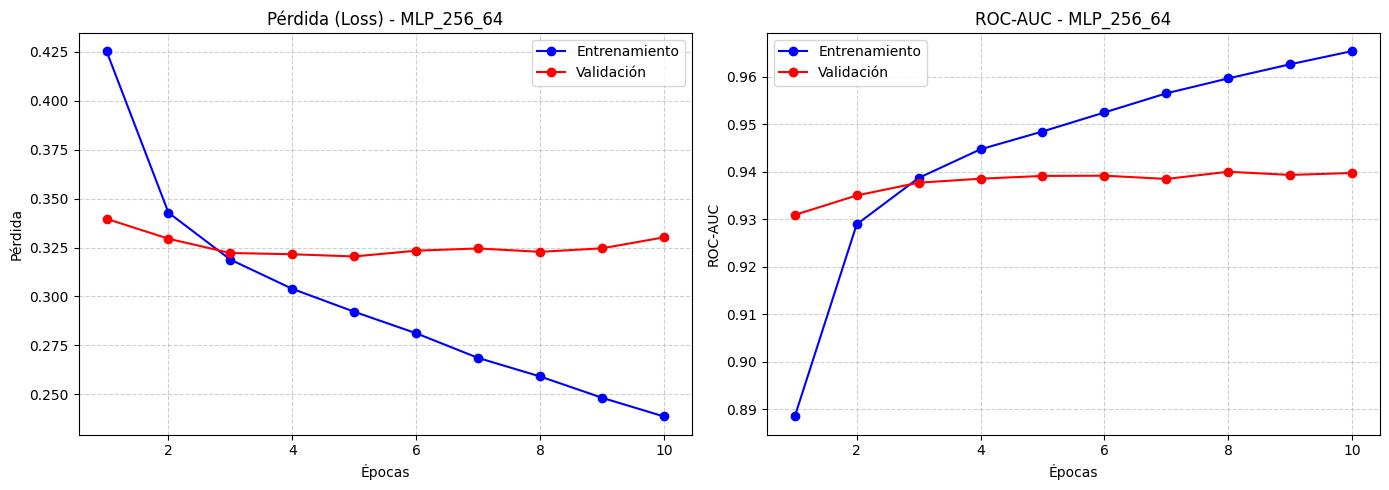

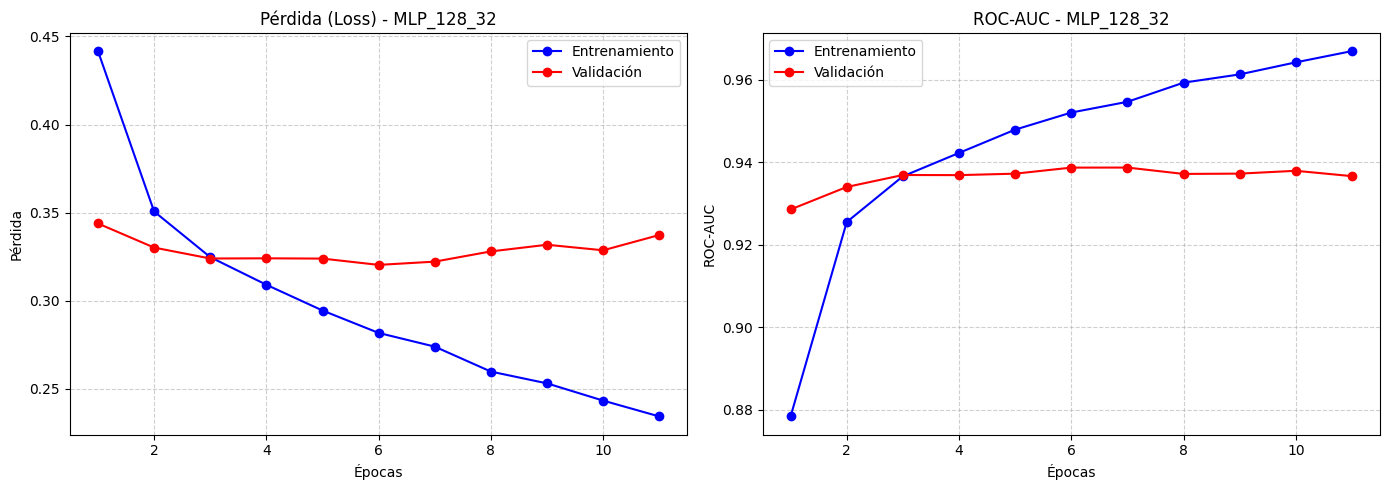

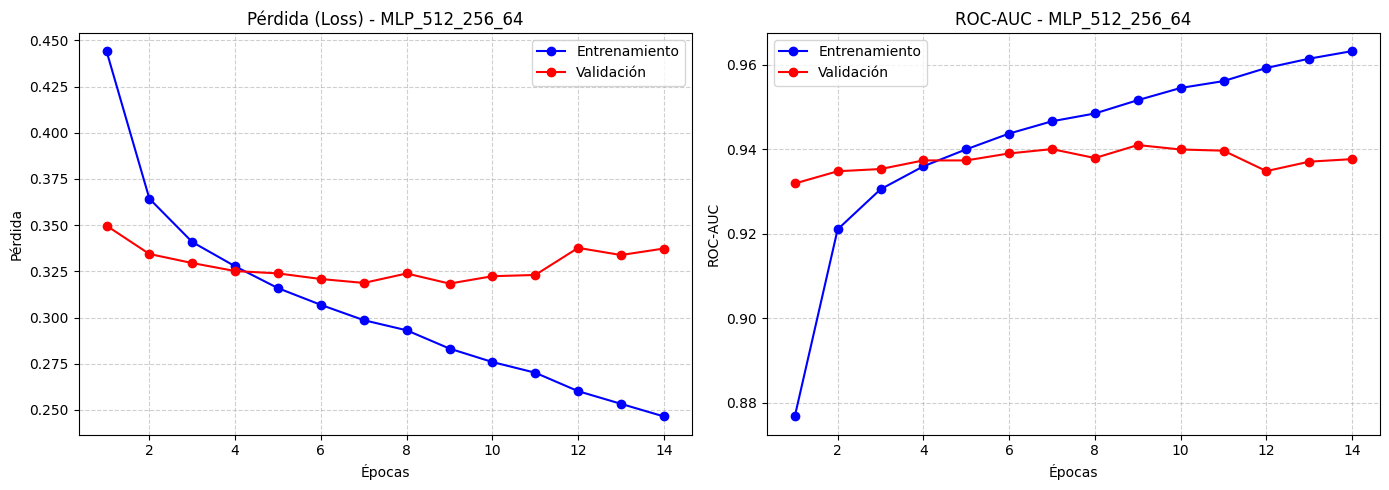

In [25]:
def graficar_historial(historial_modelo, nombre_modelo="Modelo"):
    """Grafica la pérdida y la métrica ROC-AUC de entrenamiento y validación."""
    # Extraer el diccionario de métricas del objeto History
    if hasattr(historial_modelo, 'history') and hasattr(historial_modelo.history, 'history'):
        hist = historial_modelo.history.history
    elif hasattr(historial_modelo, 'history') and isinstance(historial_modelo.history, dict):
        hist = historial_modelo.history
    elif isinstance(historial_modelo, dict):
        hist = historial_modelo
    else:
        print(f"No se pudieron extraer las métricas de {nombre_modelo}.")
        return

    epochs = range(1, len(hist['loss']) + 1)

    plt.figure(figsize=(14, 5))

    # Gráfico de Pérdida (Loss)
    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist['loss'], 'bo-', label='Entrenamiento')
    plt.plot(epochs, hist['val_loss'], 'ro-', label='Validación')
    plt.title(f'Pérdida (Loss) - {nombre_modelo}')
    plt.xlabel('Épocas')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # Gráfico de ROC-AUC
    plt.subplot(1, 2, 2)
    if 'roc_auc' in hist:
        plt.plot(epochs, hist['roc_auc'], 'bo-', label='Entrenamiento')
        plt.plot(epochs, hist['val_roc_auc'], 'ro-', label='Validación')
        plt.title(f'ROC-AUC - {nombre_modelo}')
        plt.ylabel('ROC-AUC')
    elif 'accuracy' in hist:
        plt.plot(epochs, hist['accuracy'], 'bo-', label='Entrenamiento')
        plt.plot(epochs, hist['val_accuracy'], 'ro-', label='Validación')
        plt.title(f'Exactitud (Accuracy) - {nombre_modelo}')
        plt.ylabel('Exactitud')
    else:
        print(f"No se encontraron métricas de rendimiento conocidas en {nombre_modelo}.")

    plt.xlabel('Épocas')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

# Graficar de forma separada el historial de cada arquitectura entrenada
if 'modelos_entrenados' in globals() and modelos_entrenados:
    for nombre, modelo in modelos_entrenados.items():
        if hasattr(modelo, 'history') and modelo.history is not None:
            graficar_historial(modelo, nombre)
        else:
            print(f"El modelo {nombre} no contiene historial de entrenamiento guardado.")
elif 'historial' in globals():
    graficar_historial(historial, "Modelo de Referencia")
else:
    print("No se encontraron modelos entrenados ni variables de historial disponibles para graficar.")

3.3 Evaluación del Modelo C en Dev

In [26]:
def metricas_keras(modelo, X, y):
    """Mismas métricas que `metricas()` de la Etapa 2, pero para un modelo de Keras."""
    proba = modelo.predict(X, verbose=0).ravel()
    pred  = (proba >= 0.5).astype(int)
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

# Guardamos de forma segura el mejor modelo entrenado en la variable de referencia 'mlp'
if 'modelos_entrenados' in globals() and "MLP_512_256_64" in modelos_entrenados:
    mlp = modelos_entrenados["MLP_512_256_64"]
    pred_dev_C = (mlp.predict(Xw_dev, verbose=0).ravel() >= 0.5).astype(int)
    print("Métricas de la mejor arquitectura (MLP_512_256_64) en Dev:")
    print({k: round(v, 4) for k, v in metricas_keras(mlp, Xw_dev, y_dev).items()})
    print("\nReporte de Clasificación:")
    print(classification_report(y_dev, pred_dev_C, target_names=["neg", "pos"]))
else:
    print("Error: El diccionario 'modelos_entrenados' o la arquitectura 'MLP_512_256_64' no se encuentran en el kernel.")

Métricas de la mejor arquitectura (MLP_512_256_64) en Dev:
{'Exactitud': 0.869, 'F1': 0.8714, 'AUC-ROC': np.float64(0.9412)}

Reporte de Clasificación:
              precision    recall  f1-score   support

         neg       0.88      0.85      0.87      2500
         pos       0.86      0.89      0.87      2500

    accuracy                           0.87      5000
   macro avg       0.87      0.87      0.87      5000
weighted avg       0.87      0.87      0.87      5000



3.4 Comparación con la Etapa 2: Baseline vs Modelo A vs Modelo B vs Modelo C


In [27]:
# Agregamos el Modelo C (solo métricas de Dev)
resultados["C: Word2vec promedio + MLP"] = metricas_keras(mlp, Xw_dev, y_dev)

filas = []
for nombre, datos in resultados.items():
    fila = {"Modelo": nombre}
    # Si 'datos' es una tupla, el primer elemento es Dev
    if isinstance(datos, tuple):
        m_dev = datos[0]
    else:
        m_dev = datos

    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    filas.append(fila)

tabla_final = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla_final)

# Diferencia de C respecto al mejor modelo de la Etapa 2 (B) en Dev
print("\nDiferencia C - B en Dev:")

# Extraer de forma segura las métricas de Dev para B y C
met_B = resultados["B: TF-IDF 1-2g + LR (con negación)"][0] if isinstance(resultados["B: TF-IDF 1-2g + LR (con negación)"], tuple) else resultados["B: TF-IDF 1-2g + LR (con negación)"]
met_C = resultados["C: Word2vec promedio + MLP"]

for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = met_C[k] - met_B[k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC
Modelo,,,
Baseline: BoW + Naive Bayes,0.8452,0.8396,0.9197
A: TF-IDF 1-2g + LR (sin negación),0.9132,0.9136,0.9692
B: TF-IDF 1-2g + LR (con negación),0.9102,0.9104,0.9699
C: Word2vec promedio + MLP,0.8690,0.8714,0.9412



Diferencia C - B en Dev:
  Exactitud : -0.0412
  F1        : -0.0390
  AUC-ROC   : -0.0288


### Curva ROC comparativa


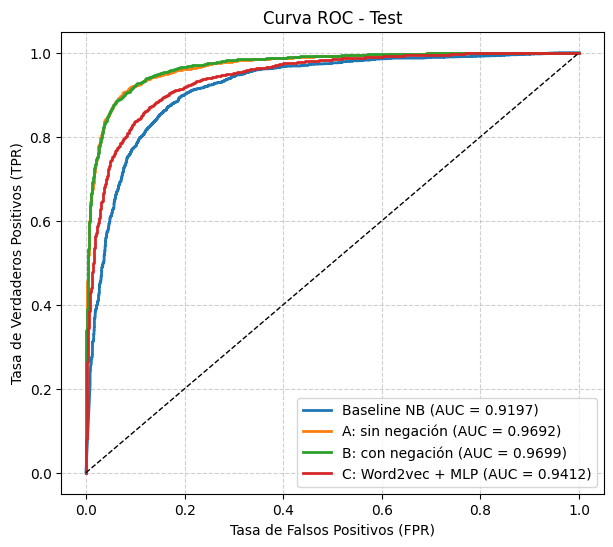

In [28]:
plt.figure(figsize=(7, 6))
for nombre, proba in [
    ("Baseline NB",       nb.predict_proba(X_dev)[:, 1]),
    ("A: sin negación",   lr_A.predict_proba(XA_dev)[:, 1]),
    ("B: con negación",   lr_B.predict_proba(XB_dev)[:, 1]),
    ("C: Word2vec + MLP", mlp.predict(Xw_dev, verbose=0).ravel()),
]:
    fpr, tpr, _ = roc_curve(y_dev, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Test")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

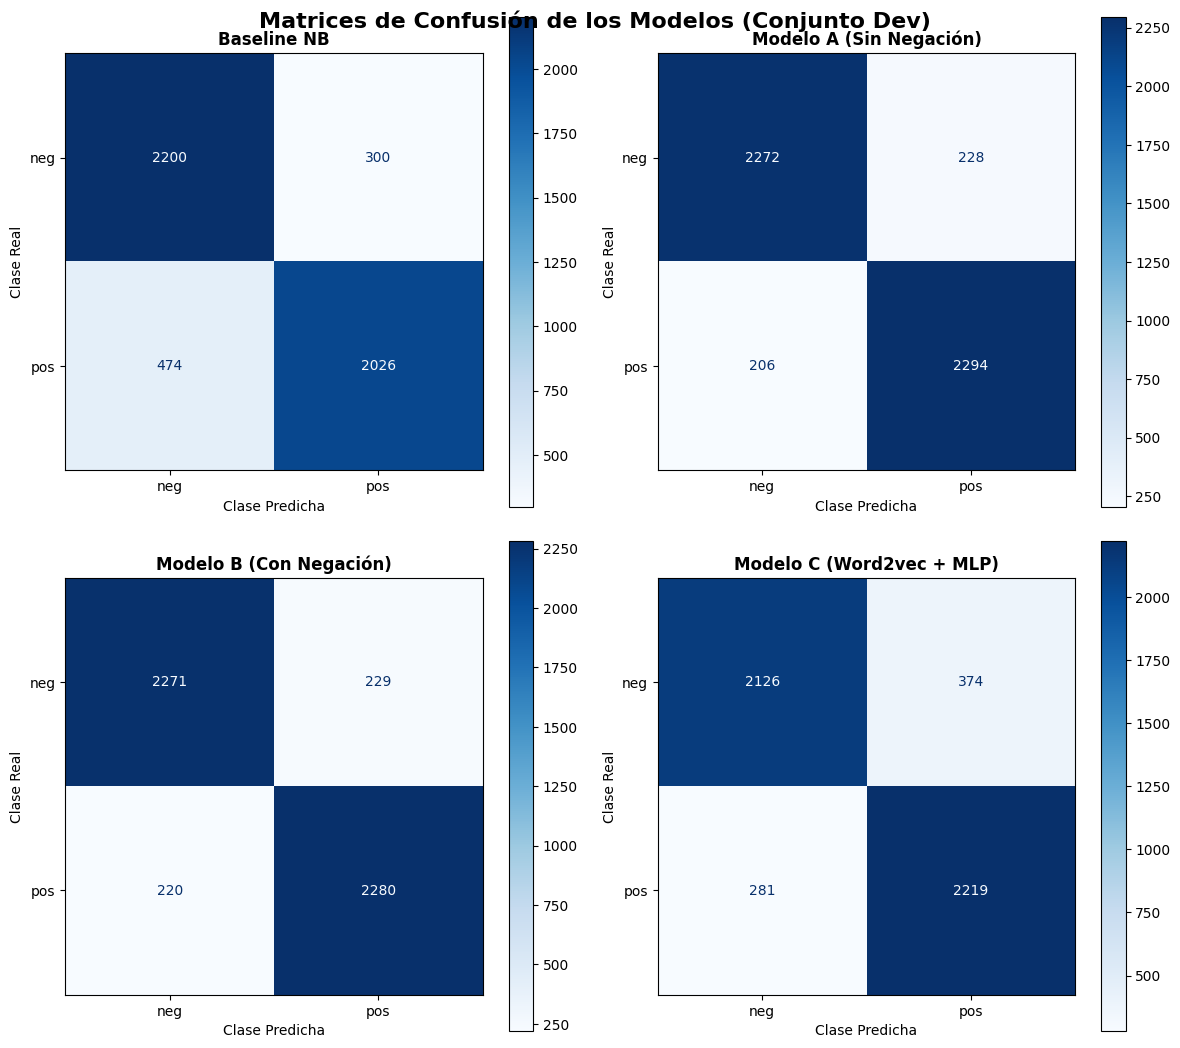

In [29]:
# 1. Obtener predicciones en Dev para todos los modelos
pred_NB = nb.predict(X_dev)
pred_A = lr_A.predict(XA_dev)
pred_B = lr_B.predict(XB_dev)

# Modelo C (MLP)
proba_C = mlp.predict(Xw_dev, verbose=0).ravel()
pred_C = (proba_C >= 0.5).astype(int)

# 2. Calcular matrices de confusión
cm_NB = confusion_matrix(y_dev, pred_NB)
cm_A = confusion_matrix(y_dev, pred_A)
cm_B = confusion_matrix(y_dev, pred_B)
cm_C = confusion_matrix(y_dev, pred_C)

# 3. Configurar la figura de 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

modelos_info = [
    ("Baseline NB", cm_NB, axes[0, 0]),
    ("Modelo A (Sin Negación)", cm_A, axes[0, 1]),
    ("Modelo B (Con Negación)", cm_B, axes[1, 0]),
    ("Modelo C (Word2vec + MLP)", cm_C, axes[1, 1])
]

for titulo, cm, ax in modelos_info:
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])
    disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Clase Predicha')
    ax.set_ylabel('Clase Real')

plt.suptitle("Matrices de Confusión de los Modelos (Conjunto Dev)", fontsize=16, fontweight='bold', y=0.96)
plt.tight_layout()
plt.show()

=== EVALUACIÓN DEFINITIVA DEL MEJOR MODELO (MODELO B) EN TEST ===
── Modelo B - Test (con negación) ──
Exactitud: 0.9044
F1:        0.9044
AUC-ROC:   0.9658

Reporte de Clasificación en Test:
              precision    recall  f1-score   support

         neg       0.90      0.90      0.90     12500
         pos       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



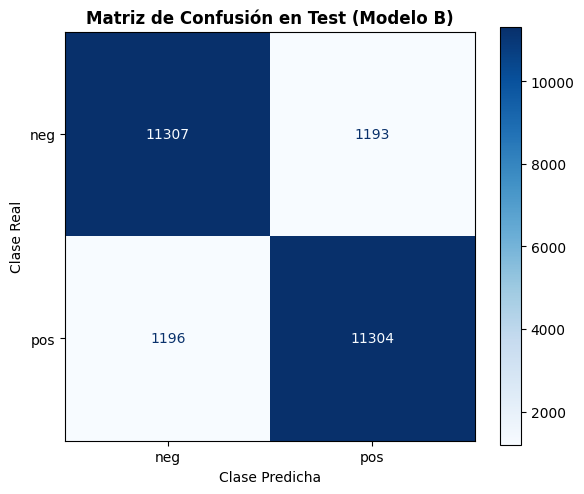

In [30]:
# 1. Transformar el conjunto de test usando el vectorizador del mejor modelo (Modelo B)
XB_test = tfidf_B.transform(test["clean_neg"])
y_test = test["sentiment"]

# 2. Evaluar el mejor modelo en el conjunto de Test
print("=== EVALUACIÓN DEFINITIVA DEL MEJOR MODELO (MODELO B) EN TEST ===")
pred_test_B = evaluar(lr_B, XB_test, y_test, "Modelo B - Test (con negación)")

print("\nReporte de Clasificación en Test:")
print(classification_report(y_test, pred_test_B, target_names=["neg", "pos"]))

# 3. Calcular y graficar la matriz de confusión para el conjunto de Test
cm_test_B = confusion_matrix(y_test, pred_test_B)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test_B, display_labels=["neg", "pos"])
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
ax.set_title('Matriz de Confusión en Test (Modelo B)', fontsize=12, fontweight='bold')
ax.set_xlabel('Clase Predicha')
ax.set_ylabel('Clase Real')
plt.tight_layout()
plt.show()

## Experimento control
"Experimento control: Vecinos más cercanos y analogías en word2vec (good <-> great); las palabras con pesos más positivos y más negativos en la regresión logistica deben ser interpretables"

In [31]:
# ===== EXPERIMENTO CONTROL (1/3): vecinos más cercanos en word2vec =====
palabras_control = ["good", "great", "bad", "terrible", "boring", "funny", "excellent"]

for p in palabras_control:
    if p in w2v.key_to_index:
        vecinos = w2v.most_similar(p, topn=8)
        print(f"{p:<10} → " + ", ".join(f"{w} ({s:.2f})" for w, s in vecinos))
    else:
        print(f"{p}: fuera del vocabulario")

print("\nSimilitud coseno entre pares de palabras:")
pares = [("good", "great"), ("good", "excellent"), ("bad", "terrible"),
         ("good", "bad"), ("great", "terrible"), ("good", "table")]
tabla_sim = pd.DataFrame(
    [(a, b, w2v.similarity(a, b)) for a, b in pares],
    columns=["palabra_1", "palabra_2", "coseno"]
).round(3)
display(tabla_sim)

good       → great (0.73), bad (0.72), terrific (0.69), decent (0.68), nice (0.68), excellent (0.64), fantastic (0.64), better (0.61)
great      → terrific (0.80), fantastic (0.79), tremendous (0.77), wonderful (0.76), good (0.73), incredible (0.70), marvelous (0.70), phenomenal (0.68)
bad        → good (0.72), terrible (0.68), horrible (0.67), Bad (0.67), lousy (0.66), crummy (0.57), horrid (0.57), awful (0.55)
terrible   → horrible (0.92), horrendous (0.85), dreadful (0.80), awful (0.75), horrid (0.72), atrocious (0.69), horrific (0.68), bad (0.68)
boring     → dull (0.74), uninteresting (0.70), monotonous (0.68), bored (0.65), bland (0.63), tedious (0.63), unexciting (0.62), tiresome (0.61)
funny      → hilarious (0.80), humorous (0.73), hilariously_funny (0.72), amusing (0.71), found_loophole_Conk (0.70), goofy (0.70), comical (0.69), witty (0.69)
excellent  → terrific (0.74), superb (0.71), exceptional (0.68), fantastic (0.68), good (0.64), great (0.61), Excellent (0.61), impeccab

,palabra_1,palabra_2,coseno
0,good,great,0.729
1,good,excellent,0.644
2,bad,terrible,0.683
3,good,bad,0.719
4,great,terrible,0.543
5,good,table,0.164


In [32]:
# ===== EXPERIMENTO CONTROL (2/3): analogías =====
def analogia(a, b, c, topn=5):
    """a es a b como c es a ?   (calcula b - a + c)"""
    res = w2v.most_similar(positive=[b, c], negative=[a], topn=topn)
    print(f"{a} : {b} :: {c} : ?  →  " + ", ".join(f"{w} ({s:.2f})" for w, s in res))

analogia("man", "king", "woman")      # control clásico de word2vec (esperado: queen)
analogia("good", "great", "bad")      # intensidad: good→great como bad→? (terrible, awful...)
analogia("good", "better", "bad")     # comparativo (esperado: worse)
analogia("good", "best", "bad")       # superlativo (esperado: worst)
analogia("good", "bad", "great")      # antónimo: good→bad como great→? (terrible, awful...)

man : king :: woman : ?  →  queen (0.71), monarch (0.62), princess (0.59), crown_prince (0.55), prince (0.54)
good : great :: bad : ?  →  terrible (0.71), horrible (0.64), unbelievable (0.55), fantastic (0.54), horrendous (0.53)
good : better :: bad : ?  →  worse (0.73), uglier (0.57), sooner (0.53), dumber (0.52), differently (0.52)
good : best :: bad : ?  →  worst (0.68), dumbest (0.53), lousiest (0.52), ugliest (0.51), nastiest (0.51)
good : bad :: great : ?  →  terrible (0.71), horrible (0.64), unbelievable (0.55), fantastic (0.54), horrendous (0.53)


In [33]:
# ===== EXPERIMENTO CONTROL (3/3): límite del promedio de embeddings con negación =====
from numpy.linalg import norm

def coseno(u, v):
    return float(np.dot(u, v) / (norm(u) * norm(v)))

frases = {"good": "this movie is good",
          "not_good": "this movie is not good",
          "bad": "this movie is bad"}

for k, t in frases.items():
    faltan = [w for w in t.split() if w not in w2v.key_to_index]
    print(f"{t!r} → palabras fuera de w2v: {faltan}")

v = {k: vector_promedio(t) for k, t in frases.items()}
print("\ncoseno('good', 'not good') :", round(coseno(v["good"], v["not_good"]), 3))
print("coseno('not good', 'bad')  :", round(coseno(v["not_good"], v["bad"]), 3))
print("coseno('good', 'bad')      :", round(coseno(v["good"], v["bad"]), 3))

'this movie is good' → palabras fuera de w2v: []
'this movie is not good' → palabras fuera de w2v: []
'this movie is bad' → palabras fuera de w2v: []

coseno('good', 'not good') : 0.969
coseno('not good', 'bad')  : 0.919
coseno('good', 'bad')      : 0.943



=== MODELO A (sin negación): 20 términos más positivos | 20 más negativos ===


,término_pos,peso_pos,término_neg,peso_neg
0,great,24.042,worst,-27.106
1,excellent,22.583,bad,-26.653
2,wonderful,16.486,awful,-24.119
3,perfect,15.515,boring,-21.959
4,fun,14.445,poor,-20.544
5,amazing,14.301,the worst,-19.510
6,enjoyable,13.466,waste,-17.593
7,the best,13.197,poorly,-16.843
8,is a,13.161,terrible,-16.737
9,today,12.668,unfortunately,-16.457



=== MODELO B (con negación): 20 términos más positivos | 20 más negativos ===


,término_pos,peso_pos,término_neg,peso_neg
0,great,21.188,bad,-25.194
1,excellent,19.486,worst,-22.457
2,fun,13.861,awful,-19.725
3,wonderful,13.467,boring,-19.004
4,amazing,12.568,poor,-16.958
5,perfect,12.202,the worst,-16.717
6,enjoyable,11.950,dull,-14.621
7,is a,11.705,unfortunately,-14.338
8,best,11.142,poorly,-14.178
9,the best,11.095,worse,-13.344


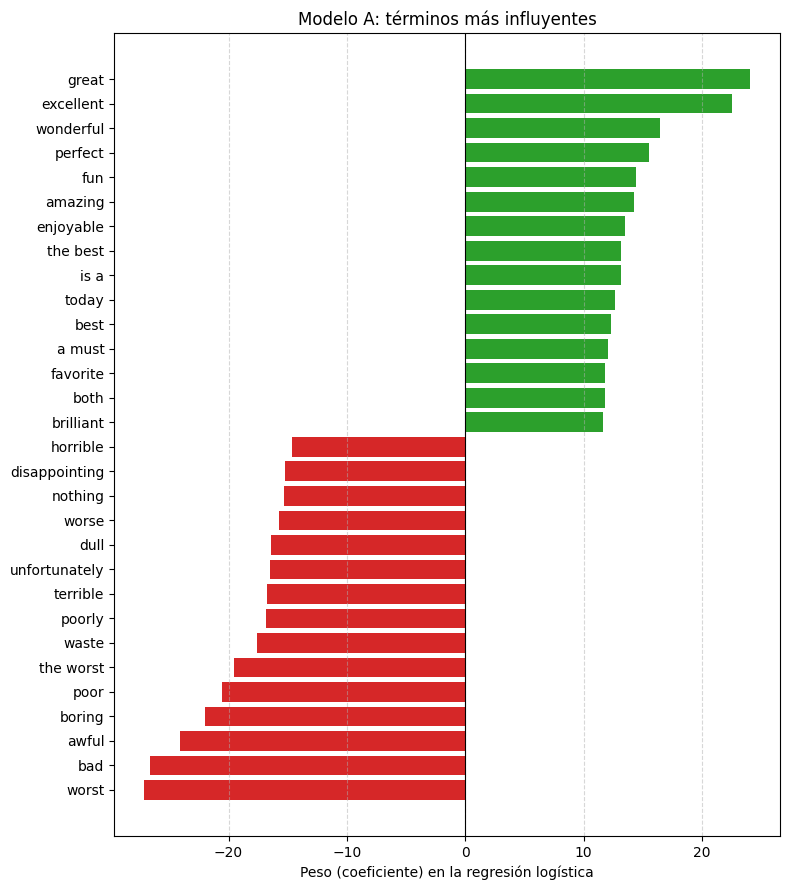

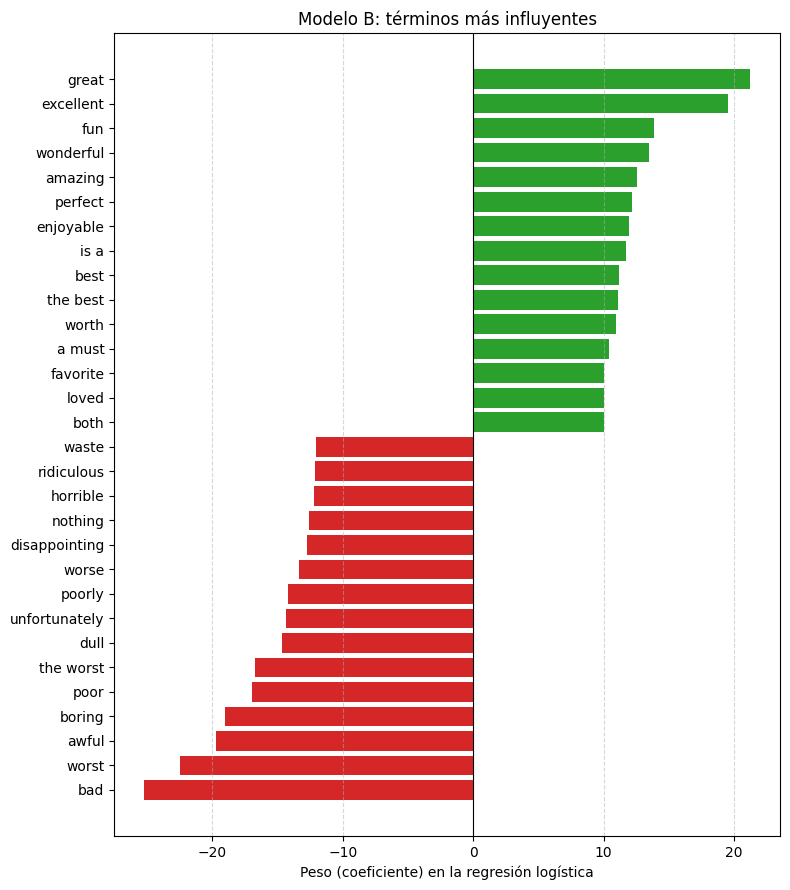

Términos con NEG_ entre los 50 de mayor |peso| del Modelo B: 2


In [34]:
# ===== PESOS DE LA REGRESIÓN LOGÍSTICA: top positivos y negativos =====
def tabla_pesos(modelo, vectorizador, k=20):
    nombres = np.array(vectorizador.get_feature_names_out())
    coefs = modelo.coef_[0]
    orden = np.argsort(coefs)
    pos = pd.DataFrame({"término": nombres[orden[-k:]][::-1], "peso": coefs[orden[-k:]][::-1]})
    neg = pd.DataFrame({"término": nombres[orden[:k]], "peso": coefs[orden[:k]]})
    return pos.round(3), neg.round(3)

for nombre, modelo, vec in [("MODELO A (sin negación)", lr_A, tfidf_A),
                            ("MODELO B (con negación)", lr_B, tfidf_B)]:
    pos_df, neg_df = tabla_pesos(modelo, vec, k=20)
    print(f"\n=== {nombre}: 20 términos más positivos | 20 más negativos ===")
    display(pd.concat([pos_df.add_suffix("_pos"), neg_df.add_suffix("_neg")], axis=1))

def graficar_pesos(modelo, vectorizador, k=15, titulo=""):
    nombres = np.array(vectorizador.get_feature_names_out())
    coefs = modelo.coef_[0]
    orden = np.argsort(coefs)
    idx = np.concatenate([orden[:k], orden[-k:]])
    terminos, pesos = nombres[idx], coefs[idx]
    colores = ["tab:red" if p < 0 else "tab:green" for p in pesos]
    plt.figure(figsize=(8, 9))
    plt.barh(terminos, pesos, color=colores)
    plt.axvline(0, color="k", lw=0.8)
    plt.title(titulo)
    plt.xlabel("Peso (coeficiente) en la regresión logística")
    plt.grid(True, axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

graficar_pesos(lr_A, tfidf_A, titulo="Modelo A: términos más influyentes")
graficar_pesos(lr_B, tfidf_B, titulo="Modelo B: términos más influyentes")

nombres_B = np.array(tfidf_B.get_feature_names_out())
top50_B = nombres_B[np.argsort(-np.abs(lr_B.coef_[0]))[:50]]
print("Términos con NEG_ entre los 50 de mayor |peso| del Modelo B:",
      sum("NEG_" in t for t in top50_B))

In [35]:
# ===== ¿EL MARCADO DE NEGACIÓN CAMBIA EL PESO? palabra vs NEG_palabra =====
vocab_A, vocab_B = tfidf_A.vocabulary_, tfidf_B.vocabulary_
cA, cB = lr_A.coef_[0], lr_B.coef_[0]

def peso(vocab, coefs, termino):
    return coefs[vocab[termino]] if termino in vocab else np.nan

base = ["good", "great", "best", "funny", "worth", "like", "interesting",
        "bad", "boring", "waste", "worst", "terrible"]
filas = [{"palabra": w,
          "A: w": peso(vocab_A, cA, w),
          "B: w": peso(vocab_B, cB, w),
          "B: NEG_w": peso(vocab_B, cB, "NEG_" + w)} for w in base]
tabla_pares = pd.DataFrame(filas).set_index("palabra").round(3)
tabla_pares["¿invierte el signo?"] = np.where(
    tabla_pares["B: NEG_w"].isna(), "n/d",
    np.where(np.sign(tabla_pares["B: w"]) != np.sign(tabla_pares["B: NEG_w"]), "sí", "no"))
display(tabla_pares)

# Bigramas de negación en el Modelo A (sin marcado)
bigramas_A = ["not good", "not bad", "not great", "not funny", "not worth",
              "no good", "didn't like", "wasn't bad"]
display(pd.DataFrame({"bigrama": bigramas_A,
                      "peso en A": [peso(vocab_A, cA, b) for b in bigramas_A]}).round(3))

,A: w,B: w,B: NEG_w,¿invierte el signo?
palabra,,,,
good,7.788,9.122,-6.457,sí
great,24.042,21.188,5.846,no
best,12.320,11.142,4.989,no
funny,2.003,5.697,-9.600,sí
worth,6.341,10.909,-9.051,sí
like,-1.312,-3.564,6.818,sí
interesting,-4.454,-2.789,-4.562,no
bad,-26.653,-25.194,-5.061,no
boring,-21.959,-19.004,-1.359,no


,bigrama,peso en A
0,not good,-4.807
1,not bad,2.247
2,not great,0.149
3,not funny,-8.694
4,not worth,-11.783
5,no good,-2.961
6,didn't like,0.642
7,wasn't bad,2.133


,n,error_NB,error_A,error_B,error_C
tipo_neg,,,,,
mixta (ambos tipos),1999.0,0.1626,0.0935,0.0985,0.1401
niega palabra negativa (not bad),1083.0,0.1459,0.0868,0.0905,0.1274
niega palabra positiva (not good),573.0,0.1606,0.1012,0.0873,0.1518
sin negación polar,1345.0,0.1480,0.0706,0.0773,0.1115
TOTAL Dev,5000.0,0.1548,0.0868,0.0898,0.1310


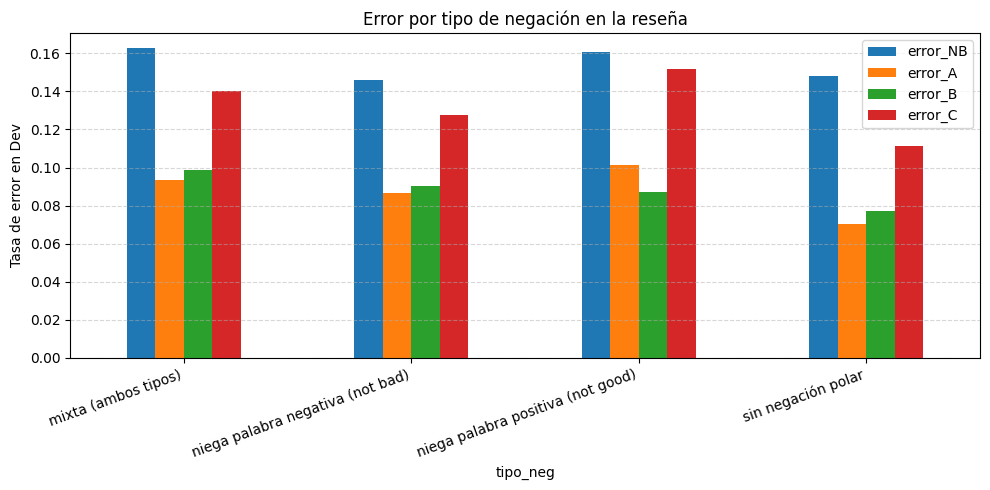

,n,error_NB,error_A,error_B,error_C
grupo_n,,,,,
0,1345,0.1480,0.0706,0.0773,0.1115
1-2,1610,0.1553,0.1006,0.0938,0.1429
3-5,1268,0.1648,0.0891,0.0962,0.1364
6 o más,777,0.1493,0.0824,0.0927,0.1313


Reseñas CON negación polar:
  errores de A corregidos por B : 59
  errores nuevos introducidos B : 65
Reseñas SIN negación polar:
  errores de A corregidos por B : 13
  errores nuevos introducidos B : 22


In [36]:
# ===== ERRORES Y NEGACIÓN (1/4): construir la tabla de análisis =====
err = dev[["review", "clean_neg", "sentiment"]].copy()
err["NB"], err["A"], err["B"], err["C"] = pred_dev, pred_dev_A, pred_dev_B, pred_dev_C
modelos = ["NB", "A", "B", "C"]
for m in modelos:
    err[f"err_{m}"] = (err[m] != err["sentiment"]).astype(int)

# Palabras polares: las 300 de mayor |peso| (unigramas) del Modelo A
nombres_A = np.array(tfidf_A.get_feature_names_out())
coefs_A = lr_A.coef_[0]
es_uni = np.array([" " not in n for n in nombres_A])
orden_abs = np.argsort(-np.abs(coefs_A[es_uni]))[:300]
polares = dict(zip(nombres_A[es_uni][orden_abs], coefs_A[es_uni][orden_abs]))

def negaciones_polares(texto_neg):
    """Cuenta tokens NEG_x donde x es polar: (niega palabra positiva, niega palabra negativa)."""
    pos = neg = 0
    for tok in texto_neg.split():
        if tok.startswith("NEG_"):
            w = tok[4:]
            if w in polares:
                if polares[w] > 0:
                    pos += 1
                else:
                    neg += 1
    return pos, neg

tmp = err["clean_neg"].apply(negaciones_polares)
err["neg_de_pos"] = tmp.str[0]
err["neg_de_neg"] = tmp.str[1]
err["neg_polar"] = err["neg_de_pos"] + err["neg_de_neg"]

def tipo_neg(r):
    if r["neg_polar"] == 0:
        return "sin negación polar"
    if r["neg_de_neg"] > 0 and r["neg_de_pos"] == 0:
        return "niega palabra negativa (not bad)"
    if r["neg_de_pos"] > 0 and r["neg_de_neg"] == 0:
        return "niega palabra positiva (not good)"
    return "mixta (ambos tipos)"

err["tipo_neg"] = err.apply(tipo_neg, axis=1)

tabla_err = err.groupby("tipo_neg").agg(
    n=("sentiment", "size"),
    error_NB=("err_NB", "mean"), error_A=("err_A", "mean"),
    error_B=("err_B", "mean"), error_C=("err_C", "mean")
).round(4)
tabla_err.loc["TOTAL Dev"] = [len(err)] + [err[f"err_{m}"].mean() for m in modelos]
display(tabla_err)

tabla_err.drop(index="TOTAL Dev")[["error_NB", "error_A", "error_B", "error_C"]].plot(
    kind="bar", figsize=(10, 5))
plt.ylabel("Tasa de error en Dev")
plt.title("Error por tipo de negación en la reseña")
plt.xticks(rotation=20, ha="right")
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Por cantidad de negaciones polares
err["grupo_n"] = pd.cut(err["neg_polar"], bins=[-1, 0, 2, 5, np.inf],
                        labels=["0", "1-2", "3-5", "6 o más"])
display(err.groupby("grupo_n", observed=True).agg(
    n=("sentiment", "size"),
    error_NB=("err_NB", "mean"), error_A=("err_A", "mean"),
    error_B=("err_B", "mean"), error_C=("err_C", "mean")).round(4))

# ¿El marcado de negación (B) corrige más de lo que rompe respecto a A?
con_neg = err["neg_polar"] > 0
corregidos = (err["err_A"] == 1) & (err["err_B"] == 0)
introducidos = (err["err_A"] == 0) & (err["err_B"] == 1)
print("Reseñas CON negación polar:")
print("  errores de A corregidos por B :", int((corregidos & con_neg).sum()))
print("  errores nuevos introducidos B :", int((introducidos & con_neg).sum()))
print("Reseñas SIN negación polar:")
print("  errores de A corregidos por B :", int((corregidos & ~con_neg).sum()))
print("  errores nuevos introducidos B :", int((introducidos & ~con_neg).sum()))

In [37]:
# ===== ERRORES Y NEGACIÓN (2/4): límites de la regla NEG_ =====
CONTRASTE = {"but", "however", "although", "though", "yet", "while"}
NEG_IMPLICITAS = {"lack", "lacks", "lacking", "fail", "fails", "failed",
                  "rarely", "seldom", "unless", "missing", "absent"}

def banderas(texto_neg, texto_orig):
    toks_neg = texto_neg.split()
    toks_plano = [t.replace("NEG_", "") for t in toks_neg]
    t = texto_orig.lower()
    return {
        # la negación "se escapa" más allá de un conector de contraste (sin puntuación)
        "alcance_excesivo": any(tok.startswith("NEG_") and tok[4:] in CONTRASTE for tok in toks_neg),
        # «not only good, but excellent»: NEG_ no invierte la polaridad
        "no_solo_es_buena": bool(re.search(r"\bnot (only|just|merely)\b", t)),
        # negaciones que la lista no contempla
        "negacion_implicita_fuera_de_lista": any(tok in NEG_IMPLICITAS for tok in toks_plano),
    }

fl = pd.DataFrame([banderas(a, b) for a, b in zip(err["clean_neg"], err["review"])],
                  index=err.index)
for c in fl.columns:
    err[c] = fl[c].values
err["niega_palabra_negativa"] = err["tipo_neg"].str.startswith("niega palabra negativa")  # «not bad»

limites = ["alcance_excesivo", "no_solo_es_buena",
           "negacion_implicita_fuera_de_lista", "niega_palabra_negativa"]
resumen = []
for c in limites:
    s, r = err[err[c]], err[~err[c]]
    resumen.append({"límite de la regla": c,
                    "n": len(s),
                    "% de Dev": round(100 * len(s) / len(err), 1),
                    "error A (con)": s["err_A"].mean(),
                    "error B (con)": s["err_B"].mean(),
                    "error B (sin)": r["err_B"].mean()})
display(pd.DataFrame(resumen).set_index("límite de la regla").round(4))

,n,% de Dev,error A (con),error B (con),error B (sin)
límite de la regla,,,,,
alcance_excesivo,749,15.0,0.0961,0.1121,0.0859
no_solo_es_buena,317,6.3,0.0536,0.0694,0.0912
negacion_implicita_fuera_de_lista,796,15.9,0.0804,0.0867,0.0904
niega_palabra_negativa,1083,21.7,0.0868,0.0905,0.0896


In [38]:
# ===== ERRORES Y NEGACIÓN (3/4): ejemplos con el fragmento negado =====
def fragmentos_neg(texto_neg, max_frag=3, max_tok=8):
    """Extrae los tramos 'negación NEG_x NEG_y ...' de una reseña marcada."""
    toks = texto_neg.split()
    frags, i = [], 1
    while i < len(toks) and len(frags) < max_frag:
        if toks[i].startswith("NEG_") and not toks[i - 1].startswith("NEG_"):
            j = i
            while j < len(toks) and toks[j].startswith("NEG_"):
                j += 1
            frag = toks[i - 1:j]
            frags.append(" ".join(frag[:max_tok]) + (" ..." if len(frag) > max_tok else ""))
            i = j
        else:
            i += 1
    return frags

def mostrar_casos(df_casos, n=5, semilla=42):
    muestra = df_casos.sample(n=min(n, len(df_casos)), random_state=semilla)
    for _, r in muestra.iterrows():
        print("=" * 90)
        print(f"Real: {'pos' if r['sentiment'] == 1 else 'neg'} | "
              f"Pred A: {'pos' if r['A'] == 1 else 'neg'} | "
              f"Pred B: {'pos' if r['B'] == 1 else 'neg'} (P(pos)={r['proba_B']:.2f}) | "
              f"{r['tipo_neg']}")
        print("Fragmentos con NEG_:", fragmentos_neg(r["clean_neg"]))
        print("Reseña:", re.sub(r"<[^>]+>", " ", r["review"])[:1000], "...")

err["proba_B"] = lr_B.predict_proba(XB_dev)[:, 1]

cand = err[(err["err_B"] == 1) & (err["neg_polar"] > 0)]
print(f"Errores de B con negación polar: {len(cand)} de {int(err['err_B'].sum())} errores totales")
print("\n>>> ERRORES DEL MODELO B EN RESEÑAS CON NEGACIÓN")
mostrar_casos(cand, n=5)

aciertos_neg = err[(err["err_A"] == 1) & (err["err_B"] == 0) & (err["neg_polar"] > 0)]
print("\n\n>>> CASOS DONDE EL MARCADO DE NEGACIÓN CORRIGIÓ UN ERROR DE A")
mostrar_casos(aciertos_neg, n=3)

Errores de B con negación polar: 345 de 449 errores totales

>>> ERRORES DEL MODELO B EN RESEÑAS CON NEGACIÓN
Real: pos | Pred A: neg | Pred B: neg (P(pos)=0.21) | niega palabra positiva (not good)
Fragmentos con NEG_: ['nothing NEG_to NEG_do NEG_with NEG_the NEG_film', 'not NEG_make NEG_an NEG_appearance NEG_as NEG_far NEG_as NEG_i ...', 'never NEG_stopped NEG_teasing NEG_or NEG_being NEG_very NEG_sexy NEG_with ...']
Reseña: In the opening scenes of this movie a man shot arrows through his hotel room into another man's bathroom and blew out all the lights. This must have been very hep for 1936, but rather way way out and had nothing to do with the film, Robin Hood did not make an appearance as far as I could see. However, Bette Davis(Daisey Appleby),"The Whales of August",'87 was very young and attractive and performed one of her best roles in a long career in Hollywood. Daisey never stopped teasing or being very sexy with her nightgowns and so called swim suit on her yacht with Georg

In [39]:
# ===== ERRORES Y NEGACIÓN (4/4): 30 errores por integrante, sin repetirse =====
from google.colab import files

errores_B = err[err["err_B"] == 1]
barajado = errores_B.sample(frac=1, random_state=42)
integrantes = ["Carlos", "Alejandra", "Nathalie"]

partes = []
for i, nombre in enumerate(integrantes):
    p = barajado.iloc[i * 30:(i + 1) * 30].copy()
    p["revisor"] = nombre
    partes.append(p)
para_etiquetar = pd.concat(partes)

salida = pd.DataFrame({
    "revisor": para_etiquetar["revisor"],
    "indice_df": para_etiquetar.index,
    "real": para_etiquetar["sentiment"].map({1: "pos", 0: "neg"}),
    "pred_B": para_etiquetar["B"].map({1: "pos", 0: "neg"}),
    "tipo_neg_auto": para_etiquetar["tipo_neg"],
    "fragmentos_NEG": para_etiquetar["clean_neg"].apply(lambda t: " | ".join(fragmentos_neg(t))),
    "resena": para_etiquetar["review"].str.replace(r"<[^>]+>", " ", regex=True).str[:700],
    "categoria_manual": "",   # negación / ironía / comparación / reseña mixta / otro
    "observaciones": "",
})
salida.to_csv("errores_B_para_etiquetar.csv", index=False)
print(salida["revisor"].value_counts())
files.download("errores_B_para_etiquetar.csv")

revisor
Carlos       30
Alejandra    30
Nathalie     30
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# ===== RESUMEN DE LA CLASIFICACIÓN MANUAL DE ERRORES =====
'''
etiquetado = pd.read_csv("errores_B_etiquetados.csv")

conteo = etiquetado.groupby(["revisor", "categoria_manual"]).size().unstack(fill_value=0)
display(conteo)

total = etiquetado["categoria_manual"].value_counts()
display((100 * total / total.sum()).round(1).rename("% de errores"))

total.plot(kind="bar", figsize=(7, 4), color="tab:blue")
plt.ylabel(f"Errores (de {len(etiquetado)})")
plt.title("Categorías de error del Modelo B (clasificación manual)")
plt.xticks(rotation=20, ha="right")
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
'''

'\netiquetado = pd.read_csv("errores_B_etiquetados.csv")\n\nconteo = etiquetado.groupby(["revisor", "categoria_manual"]).size().unstack(fill_value=0)\ndisplay(conteo)\n\ntotal = etiquetado["categoria_manual"].value_counts()\ndisplay((100 * total / total.sum()).round(1).rename("% de errores"))\n\ntotal.plot(kind="bar", figsize=(7, 4), color="tab:blue")\nplt.ylabel(f"Errores (de {len(etiquetado)})")\nplt.title("Categorías de error del Modelo B (clasificación manual)")\nplt.xticks(rotation=20, ha="right")\nplt.grid(True, axis="y", linestyle="--", alpha=0.5)\nplt.tight_layout()\nplt.show()\n'